## Modelling receiver area

In [98]:
from anemone.system import Loop, Receiver
from anemone.forwards import Forward
import matplotlib.pyplot as plt
import numpy as np
import torch

In [110]:
x_offset = 4
tx = Loop.square(3)
rx = Loop.square(3)
rx.x += x_offset

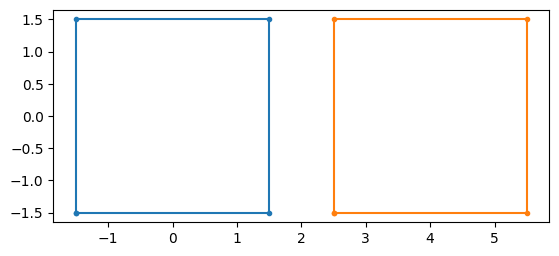

In [111]:
fig,ax = plt.subplots(1,1)
ax.plot(tx.x, tx.y, 'C0.-', label='Tx')
ax.plot(rx.x, rx.y, 'C1.-', label='Rx')
ax.set_aspect('equal')

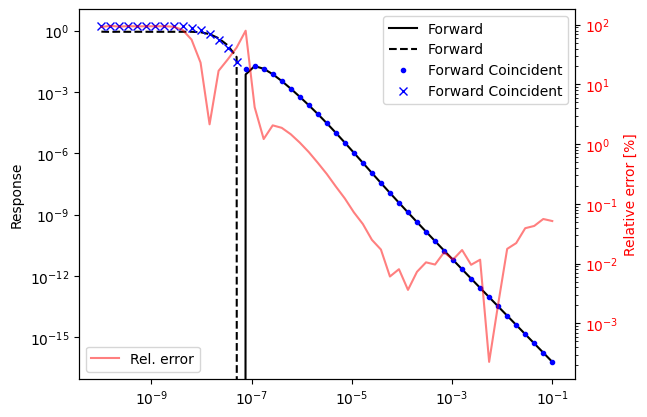

In [116]:
x,y = torch.meshgrid(torch.linspace(rx.x.min(), rx.x.max(), 7)[1:-1], torch.linspace(rx.y.min(), rx.y.max(), 7)[1:-1])

rx_prof = Receiver(x=x.flatten(), y=y.flatten(), grid=False)
weight = torch.ones_like(rx_prof.X) / rx_prof.X.numel()
rx_prof.weighting = weight

times = torch.logspace(-10, -1, 51)
fwr = Forward(tx, rx_prof, times, tolerance=None)

fwr0 = Forward(tx, Receiver(x=x_offset), times, tolerance=None)

dbdt = fwr(torch.tensor([40, 80]), torch.tensor([10])).real
dbdt0 = fwr0(torch.tensor([40, 80]), torch.tensor([10])).real

fig, ax = plt.subplots(1, 1)

ax.loglog(fwr.times,  dbdt0, 'k-', label='Forward')
ax.loglog(fwr.times, -dbdt0, 'k--', label='Forward')

ax.loglog(fwr.times,  dbdt, 'b.', label='Forward Coincident')
ax.loglog(fwr.times, -dbdt, 'bx', label='Forward Coincident')

ax.legend(loc='upper right')
ax.set_ylabel('Response')

ax2 = ax.twinx()
rel_err = ((dbdt - dbdt0) / dbdt0).abs()
ax2.loglog(fwr.times, rel_err * 100, 'r-', alpha=0.5, label='Rel. error')
ax2.set_ylabel('Relative error [%]', color='r')
ax2.tick_params(axis='y', labelcolor='r')
ax2.legend(loc='lower left')

In [4]:
tx = Loop.circle(30)
rx = Receiver(torch.linspace(0, 30, 21)[:-1])

In [78]:
times = torch.logspace(-7, -2, 51)

In [79]:
fwr = Forward(tx, rx, times, tolerance=None)

In [80]:
dbdt = fwr(torch.tensor([40, 80]), torch.tensor([10]))

In [81]:
dr = torch.gradient(rx.x)[0]
ring_area = dr * rx.x*2*np.pi
ring_area[0] = (0.5*dr[0])**2 * np.pi

In [82]:
fwr.H2t = (fwr.H2t * ring_area[None, :, None]).sum(1)

In [83]:
dbdt = fwr(torch.tensor([40, 80]), torch.tensor([10])) / ring_area.sum()

In [84]:
fwr0 = Forward(tx, Receiver(), times, tolerance=None)
dbdt0 = fwr0(torch.tensor([40, 80]), torch.tensor([10]))

In [85]:
ring_area = ring_area / ring_area.sum()

rx1 = Receiver(rx.x, weighting=ring_area)
fwr1 = Forward(tx, rx1, times, tolerance=None)
fwr1.H2t = fwr1.H2t.real

dbdt1 = fwr1(torch.tensor([40, 80]), torch.tensor([10]))

In [86]:
from anemone.physics import rte_halfspace

13783


<Figure size 640x480 with 0 Axes>

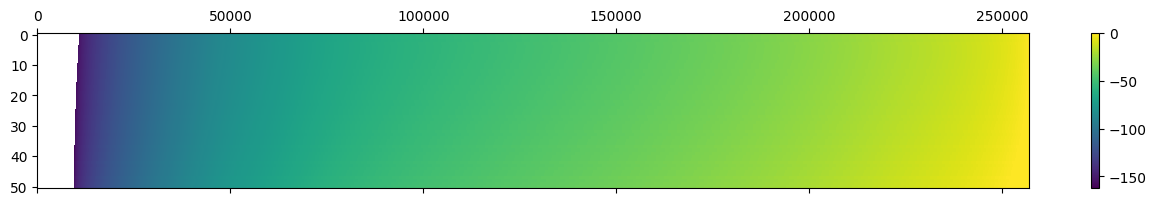

In [87]:
bigW = (fwr1.H2t*rte_halfspace(1./torch.tensor([100.]), fwr1.omega, fwr1.lamda).real).abs()#.sum(0)
i_Hsort = (bigW).sum(0).argsort()

bigWsort = bigW[:, i_Hsort]
bigWsort = bigWsort.cumsum(dim=1)/bigWsort.sum(dim=1, keepdims=True)
idx = torch.searchsorted(bigWsort, torch.ones((51,1))*1e-5, right=True).min()
i_Hsort = i_Hsort[idx:]

print(len(i_Hsort))

fwr1.H2t = fwr1.H2t[:, i_Hsort]
fwr1.omega = fwr1.omega[i_Hsort]
fwr1.lamda = fwr1.lamda[i_Hsort]

plt.figure()
pcm=plt.matshow(bigWsort.log10(), aspect='auto')
plt.colorbar(pcm)

<Figure size 640x480 with 0 Axes>

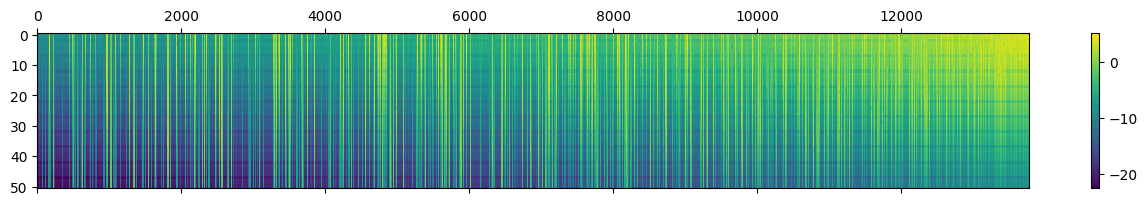

In [88]:
plt.figure()
pcm=plt.matshow(fwr1.H2t.real.abs().log10(), aspect='auto')
plt.colorbar(pcm)

In [89]:
dbdt1 = fwr1(torch.tensor([40, 80]), torch.tensor([10]))

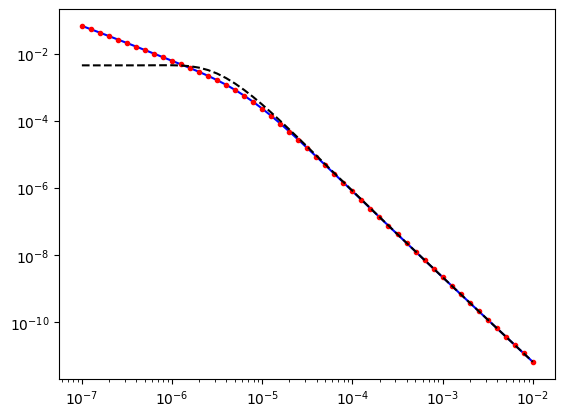

In [90]:
plt.figure()
plt.loglog(fwr.times, dbdt.real, 'b-', label='Forward Coincident')
plt.loglog(fwr.times, dbdt1.real, 'r.', label='Forward')

plt.loglog(fwr.times, dbdt0.real, 'k--', label='Forward')


In [14]:
area = 30**2 * np.pi
print(ring_area.sum(), area)

tensor(1., dtype=torch.float64) 2827.4333882308138


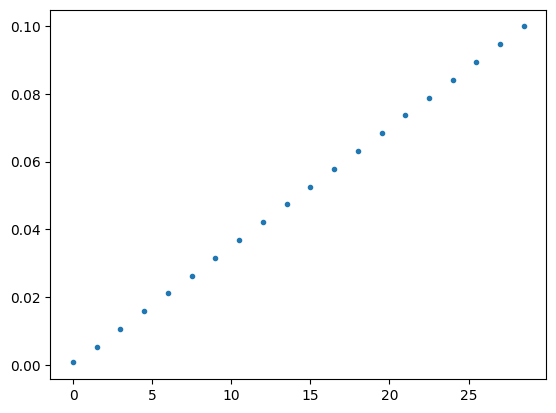

In [15]:
plt.figure()
plt.plot(rx.x, ring_area, '.')

In [16]:
dbdt.shape

torch.Size([51])